In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

for f in os.listdir('/content/drive/MyDrive'):
    print(f)

Classroom
vasanth.exe
Screenshot 2024-09-12 121530.png
Screenshot 2024-09-12 122841.png
1.pdf
Screenshot 2024-10-03 121439.png
C PROGRAMMING QUESTIONS vasanth.docx
Adobe Scan 25 Oct 2024 (1).pdf
c internal 2 my answer sheet.pdf
URK24RA4006.jpg
lec 14 water pollution lectur 14.gslides
lec 19 & 25 NUCLEAR POLLUTION PPT lec 19,25 (1).gslides
lec 16 noise pollution-lec 16 a (1).gslides
lec 15 soilpollution- (2).gslides
lec 15 soilpollution- (1).gslides
lec 16 noise pollution-lec 16 a.gslides
lec 16 thermal pollution-lec 16 b.gslides
lec 17 social issues of the environment-converted.gslides
lec 18 Environmental ethics ppt.gslides
lec 19 & 25 NUCLEAR POLLUTION PPT lec 19,25.gslides
lec 20 Environmental legislation lec 20.gslides
lec 2 renewable and non renewable resources (1).gslides
lec 2 renewable and non renewable resources.gslides
Assignment -  (6 Jan 2025 at 15:46) (1).jpg
20250106_154508 (1).jpg
Assignment -  (6 Jan 2025 at 15:46).jpg
20250106_154508.jpg
20250115_194414.jpg
Quiz (1).gs

In [3]:
import os
import zipfile

zip_path = "/content/drive/MyDrive/All_Random_Obstacles.zip"

print("File exists:", os.path.exists(zip_path))

if os.path.exists(zip_path):
    print("ZIP size (MB):", round(os.path.getsize(zip_path) / (1024 * 1024), 2))

    with zipfile.ZipFile(zip_path, "r") as z:
        print("Total items:", len(z.namelist()))
        print("Sample files:")
        print(z.namelist()[:10])

File exists: True
ZIP size (MB): 26.47
Total items: 253
Sample files:
['All Random Obstacles/', 'All Random Obstacles/10 Percent Filled/', 'All Random Obstacles/10 Percent Filled/10% Random Obstacles Metrics.xlsx', 'All Random Obstacles/10 Percent Filled/Map Images 10% Filled/', 'All Random Obstacles/10 Percent Filled/Map Images 10% Filled/random512-10-0.jpg', 'All Random Obstacles/10 Percent Filled/Map Images 10% Filled/random512-10-1.jpg', 'All Random Obstacles/10 Percent Filled/Map Images 10% Filled/random512-10-2.jpg', 'All Random Obstacles/10 Percent Filled/Map Images 10% Filled/random512-10-3.jpg', 'All Random Obstacles/10 Percent Filled/Map Images 10% Filled/random512-10-4.jpg', 'All Random Obstacles/10 Percent Filled/Map Images 10% Filled/random512-10-5.jpg']


In [4]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/All_Random_Obstacles.zip"
output_path = "/content/obstacle_dataset"

with zipfile.ZipFile(zip_path, "r") as z:
    files = [
        f for f in z.namelist()
        if "/10 Percent Filled/Map Images 10% Filled/" in f
        and f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    for f in files:
        z.extract(f, output_path)

print("Extracted map images:", len(files))
print("Dataset folder:", output_path)

Extracted map images: 10
Dataset folder: /content/obstacle_dataset


Total images: 10
Image size: (700, 700)


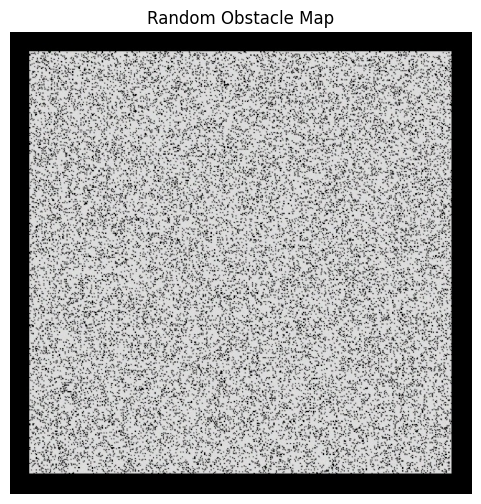

In [5]:
import os
import glob
import matplotlib.pyplot as plt
from PIL import Image

dataset_path = "/content/obstacle_dataset"

images = glob.glob(dataset_path + "/**/*.jpg", recursive=True)
images += glob.glob(dataset_path + "/**/*.png", recursive=True)

print("Total images:", len(images))

img = Image.open(images[0])
print("Image size:", img.size)

plt.figure(figsize=(6, 6))
plt.imshow(img)
plt.title("Random Obstacle Map")
plt.axis("off")
plt.show()

Total images: 10


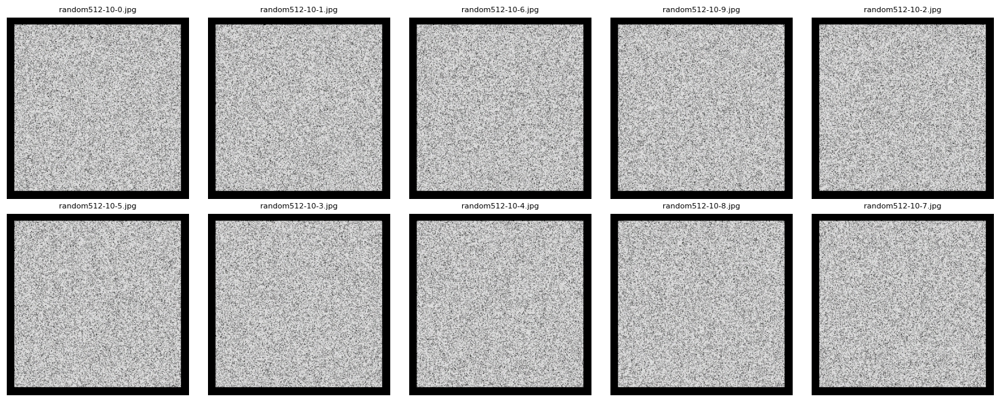

In [6]:
import glob
import matplotlib.pyplot as plt
from PIL import Image
import os
import math

dataset_path = "/content/obstacle_dataset"

images = glob.glob(dataset_path + "/**/*.jpg", recursive=True)
images += glob.glob(dataset_path + "/**/*.png", recursive=True)

print("Total images:", len(images))

cols = 5
rows = math.ceil(len(images) / cols)

plt.figure(figsize=(15, rows * 3))

for i, image_path in enumerate(images):
    img = Image.open(image_path)

    plt.subplot(rows, cols, i + 1)
    plt.imshow(img)
    plt.title(os.path.basename(image_path), fontsize=8)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [7]:
import glob
import numpy as np
from PIL import Image

dataset_path = "/content/obstacle_dataset"

images = glob.glob(dataset_path + "/**/*.jpg", recursive=True)
images += glob.glob(dataset_path + "/**/*.png", recursive=True)

X = []

for path in images:
    img = Image.open(path).convert("L").resize((128, 128))
    img_array = np.array(img) / 255.0
    X.append(img_array)

X = np.array(X)

print("Dataset shape:", X.shape)
print("Number of maps:", len(X))
print("Image size:", X.shape[1], "x", X.shape[2])

Dataset shape: (10, 128, 128)
Number of maps: 10
Image size: 128 x 128


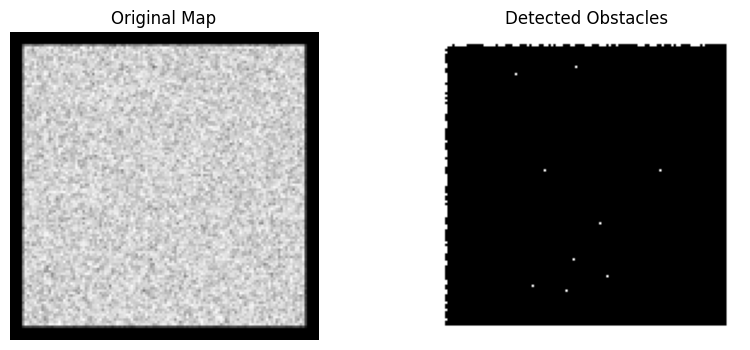

Obstacle pixels: 2812
Free-space pixels: 13572


In [8]:
import matplotlib.pyplot as plt
import numpy as np

# Select the first map
map_image = X[0]

# Convert grayscale pixels into obstacle/free-space labels
# This assumes dark pixels represent obstacles
obstacle_map = map_image < 0.5

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(map_image, cmap="gray")
plt.title("Original Map")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(obstacle_map, cmap="gray")
plt.title("Detected Obstacles")
plt.axis("off")

plt.show()

print("Obstacle pixels:", np.sum(obstacle_map))
print("Free-space pixels:", np.sum(~obstacle_map))

Free cells: 13572
Start: (np.int64(5), np.int64(8))
Goal: (np.int64(121), np.int64(121))
Path found! Length: 230


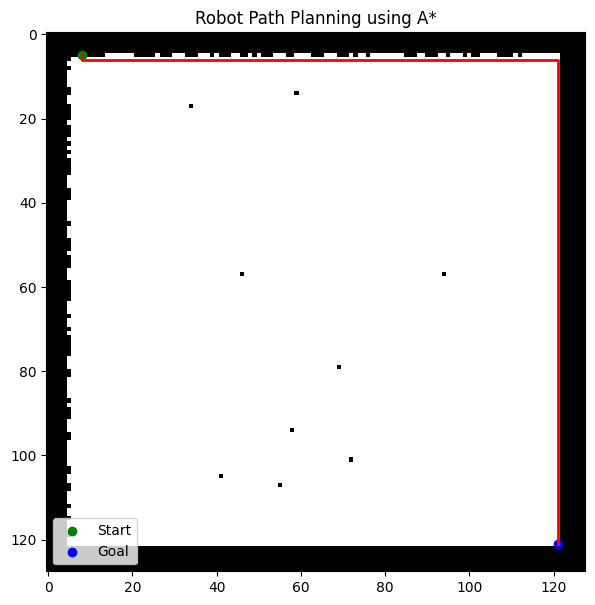

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import heapq

# Try another map
grid = X[0] < 0.5

# If most pixels are obstacles, reverse the threshold
if np.mean(grid) > 0.5:
    grid = X[0] >= 0.5

# Find free cells
free_cells = np.argwhere(~grid)

print("Free cells:", len(free_cells))

if len(free_cells) > 1:
    start = tuple(free_cells[0])
    goal = tuple(free_cells[-1])

    print("Start:", start)
    print("Goal:", goal)

    path = astar(grid, start, goal)

    if path:
        print("Path found! Length:", len(path))

        plt.figure(figsize=(7, 7))
        plt.imshow(grid, cmap="gray_r")
        rows, cols = zip(*path)
        plt.plot(cols, rows, "r-", linewidth=2)
        plt.scatter(start[1], start[0], c="green", label="Start")
        plt.scatter(goal[1], goal[0], c="blue", label="Goal")
        plt.legend()
        plt.title("Robot Path Planning using A*")
        plt.show()
    else:
        print("No path found. We need to check the map's pixel colors.")
else:
    print("Too few free cells. We need to adjust the threshold.")

Obstacle percentage: 17.16 %
SUCCESS: Path found!
Path length: 230 cells


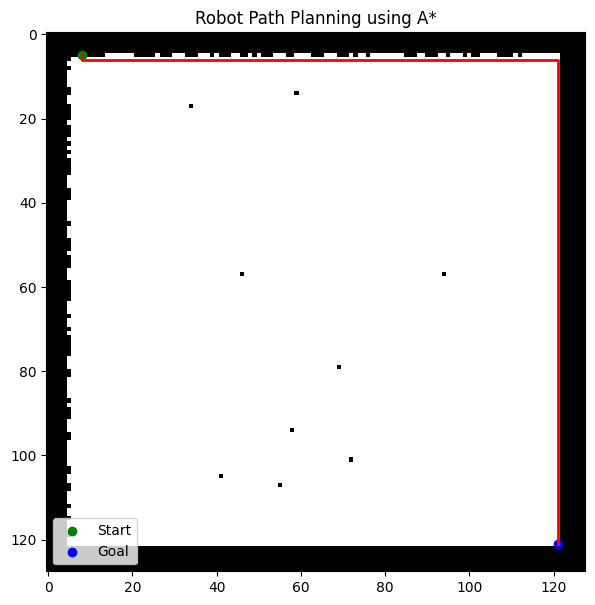

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import heapq

# Select first map
img = X[0]

# Automatically decide whether dark or bright pixels are obstacles
dark_obstacles = img < 0.5
bright_obstacles = img >= 0.5

# Choose the interpretation with fewer obstacle pixels
grid = dark_obstacles if dark_obstacles.mean() < bright_obstacles.mean() else bright_obstacles

# Find free cells
free = np.argwhere(~grid)

if len(free) < 2:
    print("Not enough free space. Please show me the original map.")
else:
    start = tuple(free[0])
    goal = tuple(free[-1])

    def astar(grid, start, goal):
        rows, cols = grid.shape
        queue = [(0, start)]
        came_from = {}
        cost = {start: 0}

        while queue:
            _, current = heapq.heappop(queue)

            if current == goal:
                path = [current]
                while current in came_from:
                    current = came_from[current]
                    path.append(current)
                return path[::-1]

            r, c = current

            for dr, dc in [(0,1), (1,0), (0,-1), (-1,0)]:
                nr, nc = r + dr, c + dc
                nxt = (nr, nc)

                if not (0 <= nr < rows and 0 <= nc < cols):
                    continue
                if grid[nr, nc]:
                    continue

                new_cost = cost[current] + 1

                if nxt not in cost or new_cost < cost[nxt]:
                    cost[nxt] = new_cost
                    priority = new_cost + abs(goal[0]-nr) + abs(goal[1]-nc)
                    came_from[nxt] = current
                    heapq.heappush(queue, (priority, nxt))

        return None

    path = astar(grid, start, goal)

    print("Obstacle percentage:", round(grid.mean() * 100, 2), "%")

    if path:
        print("SUCCESS: Path found!")
        print("Path length:", len(path), "cells")

        plt.figure(figsize=(7, 7))
        plt.imshow(grid, cmap="gray_r", origin="upper")
        r, c = zip(*path)
        plt.plot(c, r, "r-", linewidth=2)
        plt.scatter(start[1], start[0], color="green", label="Start")
        plt.scatter(goal[1], goal[0], color="blue", label="Goal")
        plt.title("Robot Path Planning using A*")
        plt.legend()
        plt.show()
    else:
        print("No path found. The map colors need checking.")

In [12]:
import numpy as np

for i, img in enumerate(X):
    dark = img < 0.5
    bright = img >= 0.5
    grid = dark if dark.mean() < bright.mean() else bright

    free = np.argwhere(~grid)

    if len(free) < 2:
        print(f"Map {i+1}: Not enough free space")
        continue

    start = tuple(free[0])
    goal = tuple(free[-1])
    path = astar(grid, start, goal)

    if path:
        print(f"Map {i+1}: Path found | Length: {len(path)} cells")
    else:
        print(f"Map {i+1}: No path found")

Map 1: Path found | Length: 230 cells
Map 2: Path found | Length: 232 cells
Map 3: Path found | Length: 232 cells
Map 4: Path found | Length: 232 cells
Map 5: Path found | Length: 227 cells
Map 6: Path found | Length: 226 cells
Map 7: Path found | Length: 232 cells
Map 8: Path found | Length: 231 cells
Map 9: Path found | Length: 226 cells
Map 10: Path found | Length: 232 cells


Total maps tested: 10
Successful paths: 10
Success rate: 100.0 %
Average path length: 230.0 cells


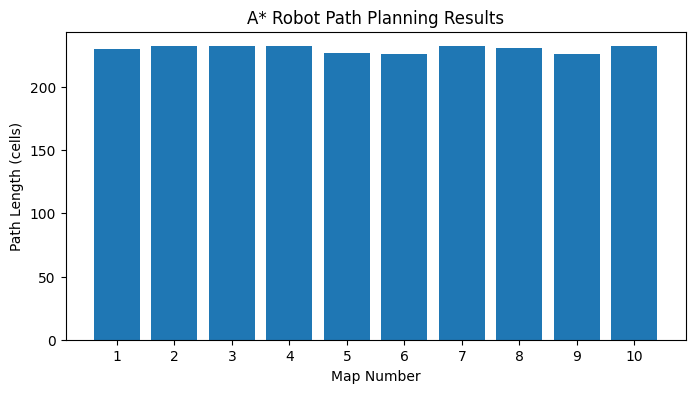

In [13]:
import numpy as np
import matplotlib.pyplot as plt

path_lengths = [230, 232, 232, 232, 227, 226, 232, 231, 226, 232]

success_count = len(path_lengths)
total_maps = 10
success_rate = (success_count / total_maps) * 100
average_length = np.mean(path_lengths)

print("Total maps tested:", total_maps)
print("Successful paths:", success_count)
print("Success rate:", success_rate, "%")
print("Average path length:", round(average_length, 2), "cells")

plt.figure(figsize=(8, 4))
plt.bar(range(1, 11), path_lengths)
plt.xlabel("Map Number")
plt.ylabel("Path Length (cells)")
plt.title("A* Robot Path Planning Results")
plt.xticks(range(1, 11))
plt.show()

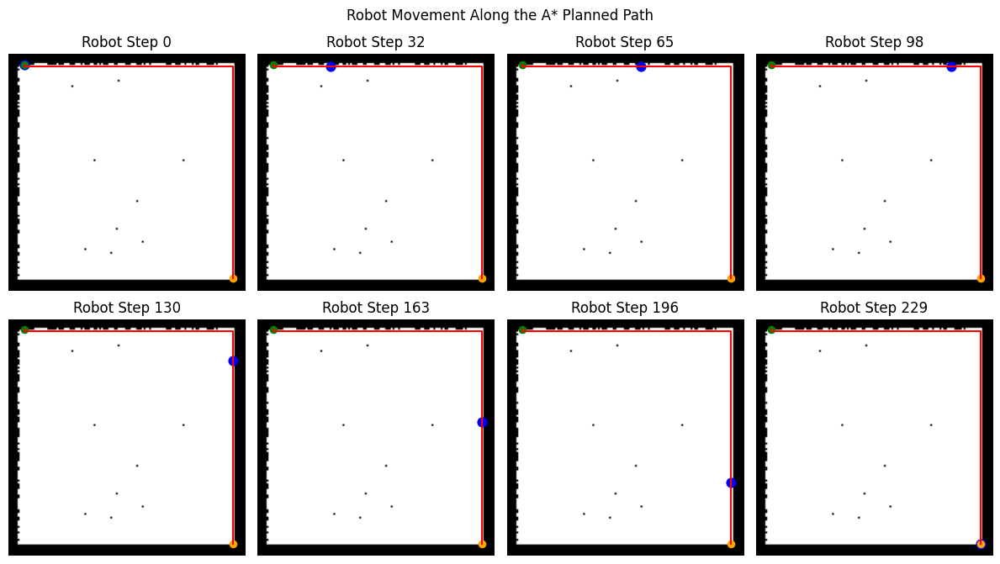

Robot movement simulation completed!


In [14]:
import matplotlib.pyplot as plt
import numpy as np

# Recalculate Map 1 and its path
img = X[0]
dark = img < 0.5
bright = img >= 0.5
grid = dark if dark.mean() < bright.mean() else bright

free = np.argwhere(~grid)
start = tuple(free[0])
goal = tuple(free[-1])

path = astar(grid, start, goal)

if path:
    # Show the robot at several positions along its route
    positions = np.linspace(0, len(path) - 1, 8, dtype=int)

    fig, axes = plt.subplots(2, 4, figsize=(12, 7))

    for i, (ax, pos) in enumerate(zip(axes.flat, positions)):
        ax.imshow(grid, cmap="gray_r")
        r, c = zip(*path)
        ax.plot(c, r, "r-", linewidth=1.5)

        robot_r, robot_c = path[pos]
        ax.scatter(robot_c, robot_r, color="blue", s=60)

        ax.scatter(start[1], start[0], color="green", s=35)
        ax.scatter(goal[1], goal[0], color="orange", s=35)

        ax.set_title(f"Robot Step {pos}")
        ax.axis("off")

    plt.suptitle("Robot Movement Along the A* Planned Path")
    plt.tight_layout()
    plt.show()

    print("Robot movement simulation completed!")
else:
    print("No path found.")

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

# Prepare Map 1
img = X[0]
dark = img < 0.5
bright = img >= 0.5
grid = dark if dark.mean() < bright.mean() else bright

free = np.argwhere(~grid)
start = tuple(free[0])
goal = tuple(free[-1])
path = astar(grid, start, goal)

if path:
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(grid, cmap="gray_r")
    rows, cols = zip(*path)
    ax.plot(cols, rows, "r--", linewidth=1, label="Planned path")
    ax.scatter(start[1], start[0], color="green", label="Start")
    ax.scatter(goal[1], goal[0], color="orange", label="Goal")

    robot, = ax.plot([], [], "bo", markersize=8, label="Robot")
    ax.legend()
    ax.set_title("Autonomous Robot Path Planning")
    ax.axis("off")

    def update(frame):
        r, c = path[frame]
        robot.set_data([c], [r])
        return robot,

    animation = FuncAnimation(
        fig, update, frames=len(path),
        interval=40, blit=True
    )

    plt.close(fig)
    display(HTML(animation.to_jshtml()))
    print("Robot animation created successfully!")
else:
    print("No path found.")

Robot animation created successfully!


In [16]:
from google.colab import files

gif_path = "/content/robot_path_planning.gif"

animation.save(gif_path, writer="pillow", fps=20)

print("Animation saved:", gif_path)

files.download(gif_path)

Animation saved: /content/robot_path_planning.gif


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [17]:
import os
import shutil

save_folder = "/content/drive/MyDrive/Robot_Obstacle_Avoidance_Project"
os.makedirs(save_folder, exist_ok=True)

shutil.copy(
    "/content/robot_path_planning.gif",
    save_folder + "/robot_path_planning.gif"
)

print("Saved to Google Drive:", save_folder)

Saved to Google Drive: /content/drive/MyDrive/Robot_Obstacle_Avoidance_Project
